In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
sns.set_style("whitegrid")

In [2]:
RAW = Path(r"C:\Users\jilu2\Desktop\intern project\code\retailpulse\data\raw\retail-project-dataset.xlsx")
PROC = Path("data/processed")
REP = Path("reports")

PROC.mkdir(parents=True, exist_ok=True)
REP.mkdir(parents=True, exist_ok=True)

print("Raw:", RAW.exists())
print("Processed dir ready:", PROC.exists())
print("Reports dir ready:", REP.exists())

Raw: True
Processed dir ready: True
Reports dir ready: True


In [3]:
df1 = pd.read_excel(RAW, sheet_name="Year 2009-2010")
df2 = pd.read_excel(RAW, sheet_name="Year 2010-2011")
df = pd.concat([df1, df2], ignore_index=True)

print("Shape:", df.shape)
df.head()

Shape: (1067371, 13)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice,InvoiceMonth,IsCancelled,DayOfWeek,CustomerType
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12,False,Tuesday,Registered
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12,False,Tuesday,Registered
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12,False,Tuesday,Registered
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12,False,Tuesday,Registered
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12,False,Tuesday,Registered


In [4]:
print("Columns:", df.columns.tolist())
df.dtypes

Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'TotalPrice', 'InvoiceMonth', 'IsCancelled', 'DayOfWeek', 'CustomerType']


Invoice                 object
StockCode               object
Description             object
Quantity                 int64
InvoiceDate     datetime64[ns]
Price                  float64
Customer ID            float64
Country                 object
TotalPrice             float64
InvoiceMonth            object
IsCancelled               bool
DayOfWeek               object
CustomerType            object
dtype: object

In [5]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
df.describe()

Shape: (1067371, 13)

Missing values:
 Invoice              0
StockCode            0
Description       4382
Quantity             0
InvoiceDate          0
Price                0
Customer ID     243007
Country              0
TotalPrice           0
InvoiceMonth         0
IsCancelled          0
DayOfWeek            0
CustomerType         0
dtype: int64

Duplicates: 34335


,Quantity,InvoiceDate,Price,Customer ID,TotalPrice
count,1.067371e+06,1067371,1.067371e+06,824364.000000,1.067371e+06
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504,1.806987e+01
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000,-1.684696e+05
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000,3.750000e+00
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000,9.900000e+00
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000,1.770000e+01
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000,1.684696e+05
std,1.727058e+02,NaN,1.235531e+02,1697.464450,2.924202e+02


In [6]:
df.columns = [c.strip().replace(" ", "") for c in df.columns]

# Rename to standard names
rename_map = {
    "Price": "UnitPrice",
    "CustomerID": "CustomerID",
    "Invoice": "InvoiceNo",
    "StockCode": "StockCode",
}
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

print("Final columns:", df.columns.tolist())

Final columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'InvoiceMonth', 'IsCancelled', 'DayOfWeek', 'CustomerType']


In [7]:
print(f"raw_rows {len(df):,}")

df = df.drop_duplicates()
print(f"after_dedup {len(df):,}")

df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["IsReturn"] = df["InvoiceNo"].str.startswith("C").astype(int)

returns = df[df["IsReturn"] == 1].copy()
sales = df[df["IsReturn"] == 0].copy()

sales = sales[(sales["Quantity"] > 0) & (sales["UnitPrice"] > 0)]
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

customer_tx = sales.dropna(subset=["CustomerID"]).copy()
customer_tx["CustomerID"] = customer_tx["CustomerID"].astype(int)

print(f"sales {len(sales):,}")
print(f"customer_transactions {len(customer_tx):,}")
print(f"returns {len(returns):,}")
print(f"dates {sales['InvoiceDate'].min().date()} to {sales['InvoiceDate'].max().date()}")

raw_rows 1,067,371
after_dedup 1,033,036
sales 1,007,913
customer_transactions 779,425
returns 19,104
dates 2009-12-01 to 2011-12-09


In [9]:
sales.to_csv(PROC / "sales.csv", index=False)
customer_tx.to_csv(PROC / "customer_transactions.csv", index=False)
returns.to_csv(PROC / "returns.csv", index=False)
print("Saved to data/processed/")

Saved to data/processed/


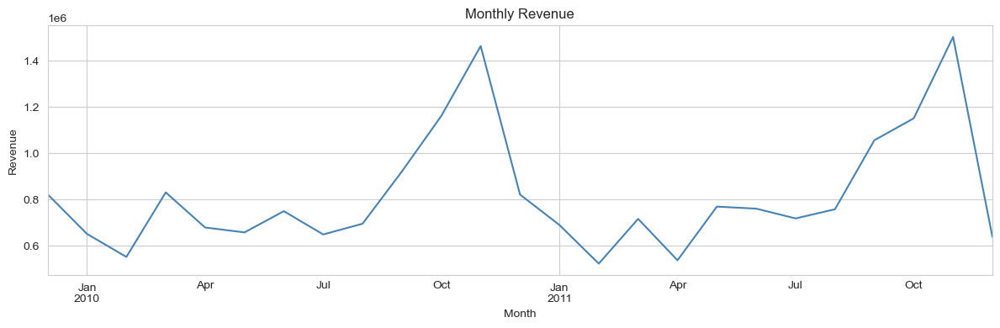

In [10]:
monthly = sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()
monthly.plot(figsize=(12, 4), title="Monthly Revenue", color="steelblue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.savefig(REP / "eda_monthly_revenue.png", dpi=100)
plt.show()

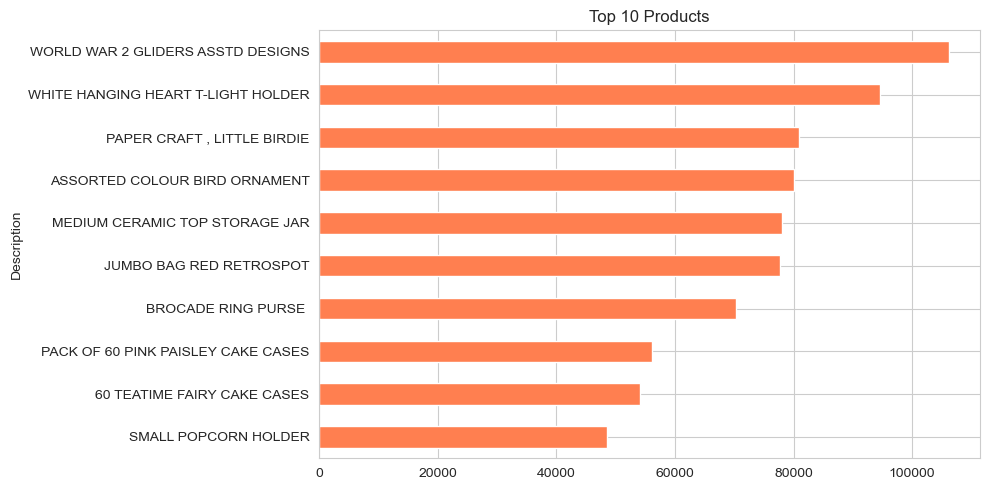

In [11]:
top = sales.groupby("Description")["Quantity"].sum().nlargest(10)
top.plot(kind="barh", figsize=(10, 5), title="Top 10 Products", color="coral")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(REP / "eda_top_products.png", dpi=100)
plt.show()

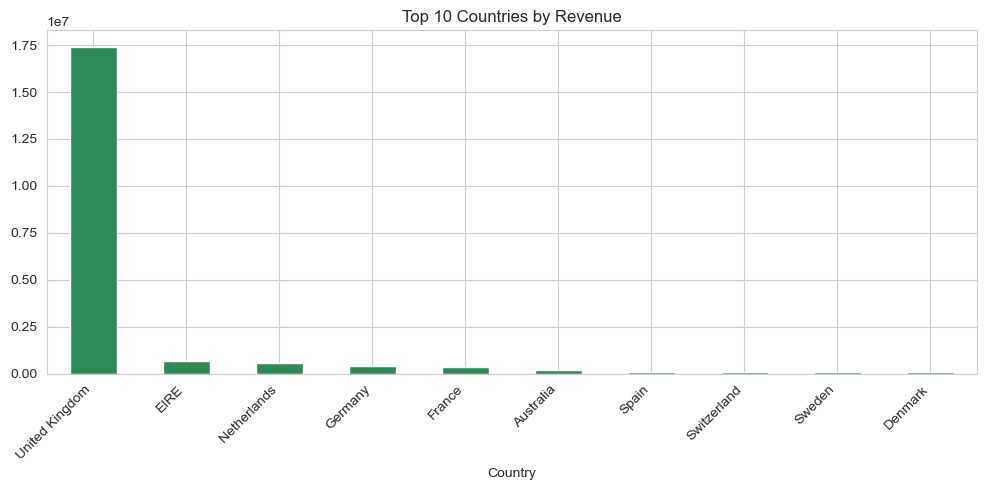

In [12]:
top_countries = sales.groupby("Country")["Revenue"].sum().nlargest(10)
top_countries.plot(kind="bar", figsize=(10, 5), title="Top 10 Countries by Revenue", color="seagreen")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(REP / "eda_top_countries.png", dpi=100)
plt.show()

In [13]:
# Load from CSV (not parquet)
customer_tx = pd.read_csv(PROC / "customer_transactions.csv")

snapshot = pd.to_datetime(customer_tx["InvoiceDate"]).max() + pd.Timedelta(days=1)
customer_tx["InvoiceDate"] = pd.to_datetime(customer_tx["InvoiceDate"])

rfm = customer_tx.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum",
})
rfm.columns = ["Recency", "Frequency", "Monetary"]
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,12,77556.46
12347,2,8,4921.53
12348,75,5,2019.40
12349,19,4,4428.69
12350,310,1,334.40


In [18]:
print("rfm columns:", rfm.columns.tolist())
print("\nrfm dtypes:\n", rfm.dtypes)
print("\nFirst rows:\n", rfm.head())

rfm columns: ['Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment']

rfm dtypes:
 Recency        int64
Frequency      int64
Monetary     float64
Cluster        int32
Segment       object
dtype: object

First rows:
             Recency  Frequency  Monetary  Cluster         Segment
CustomerID                                                       
12346           326         12  77556.46        2      High-value
12347             2          8   4921.53        2      High-value
12348            75          5   2019.40        3          Active
12349            19          4   4428.69        1  One-time buyer
12350           310          1    334.40        0         At-risk


In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Drop old cluster/segment columns if they exist (from previous runs)
rfm = rfm.drop(columns=["Cluster", "Segment"], errors="ignore")

# Use only the 3 numeric RFM columns
rfm_numeric = rfm[["Recency", "Frequency", "Monetary"]]

scaled = StandardScaler().fit_transform(np.log1p(rfm_numeric))
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = km.fit_predict(scaled)

summary = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()
labels = {}
for c in summary.index:
    r, f, m = summary.loc[c]
    if m > summary["Monetary"].median() and r < summary["Recency"].median():
        labels[c] = "High-value"
    elif r > summary["Recency"].median() and m < summary["Monetary"].median():
        labels[c] = "At-risk"
    elif f > summary["Frequency"].median():
        labels[c] = "Active"
    else:
        labels[c] = "One-time buyer"

rfm["Segment"] = rfm["Cluster"].map(labels)
print(rfm["Segment"].value_counts())

Segment
At-risk           1973
Active            1459
One-time buyer    1250
High-value        1196
Name: count, dtype: int64


In [21]:
print("rfm columns:", rfm.columns.tolist())
print("rfm dtypes:\n", rfm.dtypes)

rfm columns: ['Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment']
rfm dtypes:
 Recency        int64
Frequency      int64
Monetary     float64
Cluster        int32
Segment       object
dtype: object


In [23]:
profiles = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
).round(2)

profiles["RevenueShare%"] = (profiles["Customers"] * profiles["AvgMonetary"] / (profiles["Customers"] * profiles["AvgMonetary"]).sum() * 100).round(1)

print(profiles)
profiles.to_csv(REP / "segment_profiles.csv")
rfm.to_csv(REP / "customer_segments.csv")

                Customers  AvgRecency  AvgFrequency  AvgMonetary  \
Segment                                                            
Active               1459      230.07          5.06      1948.50   
At-risk              1973      394.95          1.38       317.08   
High-value           1196       27.71         19.28     10731.16   
One-time buyer       1250       28.30          3.05       857.49   

                RevenueShare%  
Segment                        
Active                   16.4  
At-risk                   3.6  
High-value               73.9  
One-time buyer            6.2  


In [24]:
profiles = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
).round(2)

profiles["RevenueShare%"] = (profiles["Customers"] * profiles["AvgMonetary"] / (profiles["Customers"] * profiles["AvgMonetary"]).sum() * 100).round(1)

print(profiles)
profiles.to_csv(REP / "segment_profiles.csv")
rfm.to_csv(REP / "customer_segments.csv")
print("\nSaved segment_profiles.csv and customer_segments.csv")

                Customers  AvgRecency  AvgFrequency  AvgMonetary  \
Segment                                                            
Active               1459      230.07          5.06      1948.50   
At-risk              1973      394.95          1.38       317.08   
High-value           1196       27.71         19.28     10731.16   
One-time buyer       1250       28.30          3.05       857.49   

                RevenueShare%  
Segment                        
Active                   16.4  
At-risk                   3.6  
High-value               73.9  
One-time buyer            6.2  

Saved segment_profiles.csv and customer_segments.csv


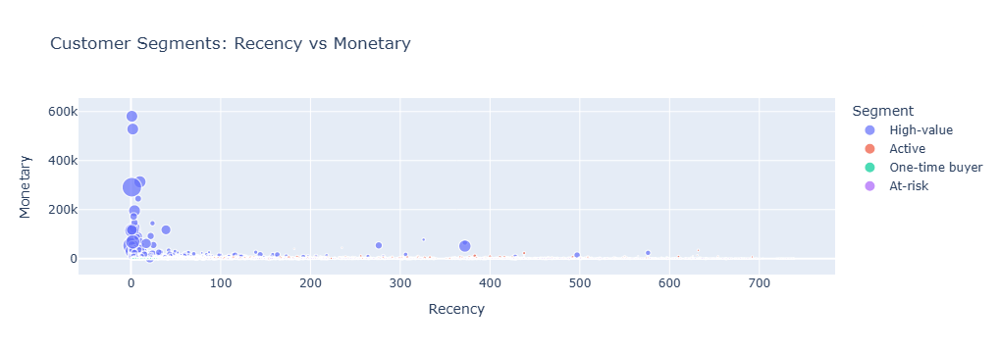

In [25]:
import plotly.express as px

fig = px.scatter(
    rfm.reset_index(),
    x="Recency", y="Monetary",
    color="Segment", size="Frequency",
    hover_data=["CustomerID"],
    title="Customer Segments: Recency vs Monetary",
)
fig.write_html(REP / "segments_scatter.html")
fig.show()

In [26]:
customer_tx = pd.read_csv(PROC / "customer_transactions.csv")
customer_tx["InvoiceDate"] = pd.to_datetime(customer_tx["InvoiceDate"])

CHURN_DAYS = 60
snapshot = customer_tx["InvoiceDate"].max()

churn_df = customer_tx.groupby("CustomerID").agg(
    TotalOrders=("InvoiceNo", "nunique"),
    TotalSpend=("Revenue", "sum"),
    AvgOrderValue=("Revenue", "mean"),
    TotalItems=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    LastPurchase=("InvoiceDate", "max"),
)
churn_df["RecencyDays"] = (snapshot - churn_df["LastPurchase"]).dt.days
churn_df["Churned"] = (churn_df["RecencyDays"] > CHURN_DAYS).astype(int)
churn_df = churn_df.drop(columns=["LastPurchase"])

print("Churn rate:", round(churn_df["Churned"].mean() * 100, 2), "%")
churn_df.head()


Churn rate: 58.8 %


,TotalOrders,TotalSpend,AvgOrderValue,TotalItems,UniqueProducts,RecencyDays,Churned
CustomerID,,,,,,,
12346,12,77556.46,2281.072353,74285,27,325,1
12347,8,4921.53,22.169054,2967,126,1,0
12348,5,2019.40,39.596078,2714,25,74,1
12349,4,4428.69,25.306800,1624,138,18,0
12350,1,334.40,19.670588,197,17,309,1


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

X = churn_df.drop(columns=["Churned"])
y = churn_df["Churned"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced"),
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probs)
    results.append({"Model": name, "ROC_AUC": round(auc, 4)})
    print(f"\n{name}: AUC = {auc:.4f}")
    print(classification_report(y_test, m.predict(X_test)))

pd.DataFrame(results).to_csv(REP / "churn_metrics.csv", index=False)
print("\nSaved churn_metrics.csv")


LogisticRegression: AUC = 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       485
           1       1.00      1.00      1.00       691

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176


RandomForest: AUC = 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       485
           1       1.00      1.00      1.00       691

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176


Saved churn_metrics.csv


In [28]:
best = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
best.fit(X, y)
churn_df["ChurnProbability"] = best.predict_proba(X)[:, 1]

churn_df.sort_values("ChurnProbability", ascending=False).head(100).to_csv(
    REP / "churn_risk_list.csv"
)
print("Saved churn_risk_list.csv")
churn_df.sort_values("ChurnProbability", ascending=False).head(10)

Saved churn_risk_list.csv


,TotalOrders,TotalSpend,AvgOrderValue,TotalItems,UniqueProducts,RecencyDays,Churned,ChurnProbability
CustomerID,,,,,,,,
12350,1,334.40,19.670588,197,17,309,1,1.0
18286,2,1296.43,19.349701,608,67,476,1,1.0
12351,1,300.93,14.330000,261,21,374,1,1.0
18285,1,427.00,35.583333,145,12,660,1,1.0
12348,5,2019.40,39.596078,2714,25,74,1,1.0
18269,1,168.60,24.085714,76,7,365,1,1.0
18268,6,1490.23,22.242239,711,36,133,1,1.0
18267,1,269.37,15.845294,135,17,672,1,1.0
15617,3,828.55,19.727381,485,41,395,1,1.0


In [29]:
sales = pd.read_csv(PROC / "sales.csv")
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

daily = sales.groupby(sales["InvoiceDate"].dt.date)["Revenue"].sum().reset_index()
daily.columns = ["ds", "y"]
daily["ds"] = pd.to_datetime(daily["ds"])
print("Daily rows:", len(daily))
daily.head()

Daily rows: 604


,ds,y
0,2009-12-01,54351.23
1,2009-12-02,63172.58
2,2009-12-03,73972.45
3,2009-12-04,40582.32
4,2009-12-05,9803.05


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

H = 30
train = daily.iloc[:-H]
test = daily.iloc[-H:]

def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"MAE": round(mae, 2), "RMSE": round(rmse, 2)}

results = {
    "Naive": evaluate(test["y"], np.full(H, train["y"].values[-1])),
    "MovingAvg_7d": evaluate(test["y"], np.full(H, train["y"].values[-7:].mean())),
}
print(results)

{'Naive': {'MAE': 18868.84, 'RMSE': np.float64(31722.28)}, 'MovingAvg_7d': {'MAE': 22605.94, 'RMSE': np.float64(35989.1)}}


In [32]:
!pip install prophet

  Using cached prophet-1.5.0-py3-none-win_amd64.whl.metadata (3.7 kB)
  Using cached cmdstanpy-1.3.0-py3-none-any.whl.metadata (4.2 kB)
  Using cached holidays-0.106-py3-none-any.whl.metadata (56 kB)
  Using cached stanio-0.5.1-py3-none-any.whl.metadata (1.6 kB)
Using cached prophet-1.5.0-py3-none-win_amd64.whl (12.1 MB)
Using cached holidays-0.106-py3-none-any.whl (1.7 MB)
Using cached cmdstanpy-1.3.0-py3-none-any.whl (99 kB)
Using cached stanio-0.5.1-py3-none-any.whl (8.1 kB)

   ---------------------------------------- 0/4 [stanio]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/

In [33]:
from prophet import Prophet

m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
m.fit(train)
future = m.make_future_dataframe(periods=H)
forecast = m.predict(future)

preds = forecast.tail(H)["yhat"].values
results["Prophet"] = evaluate(test["y"], preds)

table = pd.DataFrame(results).T
table.index.name = "Model"
print(table)
table.to_csv(REP / "forecast_total_metrics.csv")
print("\nSaved forecast_total_metrics.csv")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
18:47:57 - cmdstanpy - INFO - Chain [1] start processing
18:48:00 - cmdstanpy - INFO - Chain [1] done processing


                   MAE      RMSE
Model                           
Naive         18868.84  31722.28
MovingAvg_7d  22605.94  35989.10
Prophet       28000.83  42900.78

Saved forecast_total_metrics.csv


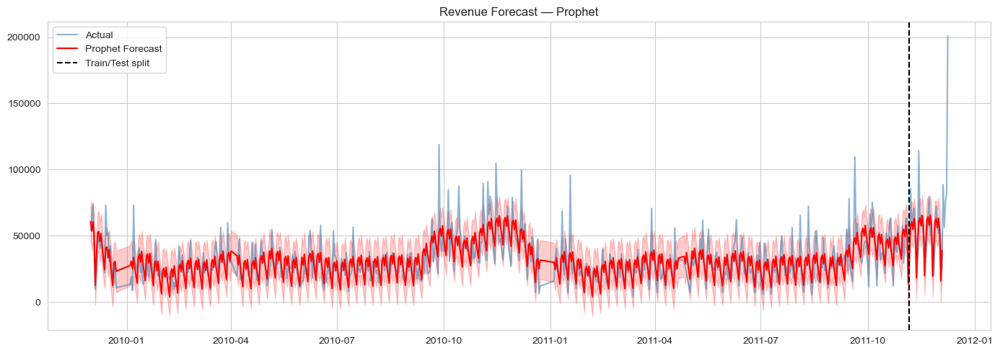

In [34]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily["ds"], daily["y"], label="Actual", color="steelblue", alpha=0.6)
ax.plot(forecast["ds"], forecast["yhat"], label="Prophet Forecast", color="red")
ax.fill_between(forecast["ds"], forecast["yhat_lower"], forecast["yhat_upper"], alpha=0.2, color="red")
ax.axvline(test["ds"].iloc[0], color="black", linestyle="--", label="Train/Test split")
ax.set_title("Revenue Forecast — Prophet")
ax.legend()
plt.tight_layout()
plt.savefig(REP / "forecast_total.png", dpi=100)
plt.show()

In [35]:
sales = pd.read_csv(PROC / "sales.csv")
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

top_skus = sales.groupby("StockCode")["Quantity"].sum().nlargest(50).index

rows = []
for sku in top_skus:
    s = sales[sales["StockCode"] == sku]
    daily_sku = s.groupby(s["InvoiceDate"].dt.date)["Quantity"].sum()
    rows.append({
        "StockCode": sku,
        "AvgDaily7d": round(daily_sku.tail(7).mean(), 2),
        "AvgDaily30d": round(daily_sku.tail(30).mean(), 2),
        "TotalSold": int(daily_sku.sum()),
    })

pf = pd.DataFrame(rows)
pf.to_csv(REP / "product_forecast.csv", index=False)
print("Saved product_forecast.csv")
pf.head()

Saved product_forecast.csv


,StockCode,AvgDaily7d,AvgDaily30d,TotalSold
0,84077,195.29,187.93,106139
1,85099B,136.57,205.83,96757
2,21212,61.43,74.97,94884
3,85123A,110.57,141.80,94203
4,22197,848.29,600.57,88499


In [36]:
LEAD_TIME = 7
SAFETY = 0.2

def recommend(sku, forecast_7d, current_stock):
    safety_stock = SAFETY * forecast_7d
    rop = forecast_7d + safety_stock
    if current_stock <= rop:
        return {"StockCode": sku, "CurrentStock": current_stock,
                "Forecast7d": round(forecast_7d), "ReorderPoint": round(rop),
                "Action": "REORDER", "OrderQty": round(max(0, rop - current_stock))}
    return {"StockCode": sku, "CurrentStock": current_stock,
            "Forecast7d": round(forecast_7d), "ReorderPoint": round(rop),
            "Action": "OK", "OrderQty": 0}

rows = []
for _, row in pf.iterrows():
    forecast_7d = row["AvgDaily7d"] * LEAD_TIME
    current_stock = int(row["AvgDaily30d"] * 15)
    rows.append(recommend(row["StockCode"], forecast_7d, current_stock))

inv = pd.DataFrame(rows)
inv.to_csv(REP / "inventory_recommendations.csv", index=False)
print(f"{len(inv[inv['Action']=='REORDER'])} of {len(inv)} SKUs flagged for reorder")
inv.head(10)

0 of 50 SKUs flagged for reorder


,StockCode,CurrentStock,Forecast7d,ReorderPoint,Action,OrderQty
0,84077,2818,1367,1640,OK,0
1,85099B,3087,956,1147,OK,0
2,21212,1124,430,516,OK,0
3,85123A,2127,774,929,OK,0
4,22197,9008,5938,7126,OK,0
5,23843,1214925,566965,680358,OK,0
6,84879,2918,1242,1490,OK,0
7,23166,447,207,248,OK,0
8,17003,1592,297,356,OK,0
9,21977,801,221,265,OK,0


In [39]:
print("=" * 50)
print("RETAILPULSE — PIPELINE COMPLETE")
print("=" * 50)
print(f"\nEDA:")
print(f"  - Total records: {len(df):,}")
print(f"  - Sales records: {len(sales):,}")
print(f"  - Customers: {rfm.shape[0]:,}")
print(f"\nSegmentation:")
for seg, count in rfm['Segment'].value_counts().items():
    print(f"  - {seg}: {count:,}")
print(f"\nChurn:")
print(f"  - Churn rate: {churn_df['Churned'].mean()*100:.1f}%")
print(f"\nForecast:")
print(table)
print(f"\nInventory:")
print(f"  - {len(inv[inv['Action']=='REORDER'])} SKUs need reorder")
print(f"\nAll reports saved in reports/")

RETAILPULSE — PIPELINE COMPLETE

EDA:
  - Total records: 1,033,036
  - Sales records: 1,007,913
  - Customers: 5,878

Segmentation:
  - At-risk: 1,973
  - Active: 1,459
  - One-time buyer: 1,250
  - High-value: 1,196

Churn:
  - Churn rate: 58.8%

Forecast:
                   MAE      RMSE
Model                           
Naive         18868.84  31722.28
MovingAvg_7d  22605.94  35989.10
Prophet       28000.83  42900.78

Inventory:
  - 0 SKUs need reorder

All reports saved in reports/


In [40]:
import os
print(sorted(os.listdir("reports")))

['churn_metrics.csv', 'churn_risk_list.csv', 'customer_segments.csv', 'eda_monthly_revenue.png', 'eda_top_countries.png', 'eda_top_products.png', 'forecast_total.png', 'forecast_total_metrics.csv', 'inventory_recommendations.csv', 'product_forecast.csv', 'segment_profiles.csv', 'segments_scatter.html']


In [42]:
from pathlib import Path
Path("app").mkdir(exist_ok=True)

dashboard_code = '''import streamlit as st
import pandas as pd
import plotly.express as px
from pathlib import Path

REP = Path("reports")
st.set_page_config(page_title="RetailPulse", layout="wide")
st.title("RetailPulse - AI Retail Analytics")

tab1, tab2, tab3, tab4 = st.tabs(["Forecast", "Segments", "Churn", "Inventory"])

with tab1:
    st.header("Demand Forecast")
    f = REP / "forecast_total_metrics.csv"
    if f.exists():
        st.dataframe(pd.read_csv(f))
    else:
        st.warning("Run forecast first.")

with tab2:
    st.header("Customer Segments")
    f = REP / "customer_segments.csv"
    if f.exists():
        seg = pd.read_csv(f)
        counts = seg["Segment"].value_counts().reset_index()
        counts.columns = ["Segment", "Count"]
        st.plotly_chart(px.bar(counts, x="Segment", y="Count", color="Segment"),
                        use_container_width=True)
        st.dataframe(seg.head(50))
    else:
        st.warning("Run segmentation first.")

with tab3:
    st.header("Churn Risk")
    f = REP / "churn_risk_list.csv"
    if f.exists():
        churn = pd.read_csv(f)
        threshold = st.slider("Churn probability threshold", 0.0, 1.0, 0.5)
        st.metric("High-risk customers", int((churn["ChurnProbability"] > threshold).sum()))
        st.dataframe(churn)
    else:
        st.warning("Run churn first.")

with tab4:
    st.header("Inventory Recommendations")
    f = REP / "inventory_recommendations.csv"
    if f.exists():
        inv = pd.read_csv(f)
        reorder = inv[inv["Action"] == "REORDER"]
        st.warning(f"{len(reorder)} SKUs need reorder")
        st.dataframe(inv)
    else:
        st.warning("Run inventory first.")
'''

with open("app/dashboard.py", "w", encoding="utf-8") as f:
    f.write(dashboard_code)
print("Created app/dashboard.py")

Created app/dashboard.py


In [43]:
!pip install streamlit plotly

In [44]:
import os
print(sorted(os.listdir("reports")))

['churn_metrics.csv', 'churn_risk_list.csv', 'customer_segments.csv', 'eda_monthly_revenue.png', 'eda_top_countries.png', 'eda_top_products.png', 'forecast_total.png', 'forecast_total_metrics.csv', 'inventory_recommendations.csv', 'product_forecast.csv', 'segment_profiles.csv', 'segments_scatter.html']


In [45]:
import os
print("reports/ contains:")
for f in sorted(os.listdir("reports")):
    print(" -", f)

reports/ contains:
 - churn_metrics.csv
 - churn_risk_list.csv
 - customer_segments.csv
 - eda_monthly_revenue.png
 - eda_top_countries.png
 - eda_top_products.png
 - forecast_total.png
 - forecast_total_metrics.csv
 - inventory_recommendations.csv
 - product_forecast.csv
 - segment_profiles.csv
 - segments_scatter.html


In [46]:
import os
from pathlib import Path

print("Current folder:", os.getcwd())
print("\nDoes reports/ exist?", Path("reports").exists())

if Path("reports").exists():
    print("\nFiles in reports/:")
    for f in sorted(os.listdir("reports")):
        print(" -", f)
else:
    print("reports/ folder does NOT exist in current folder")

# Search everywhere for these files
print("\nSearching for the CSVs...")
for root, dirs, files in os.walk("."):
    if "venv" in root or ".venv" in root:
        continue
    for f in files:
        if f.endswith((".csv", ".png", ".html")):
            print(f"Found: {os.path.join(root, f)}")

Current folder: C:\Users\jilu2

Does reports/ exist? True

Files in reports/:
 - churn_metrics.csv
 - churn_risk_list.csv
 - customer_segments.csv
 - eda_monthly_revenue.png
 - eda_top_countries.png
 - eda_top_products.png
 - forecast_total.png
 - forecast_total_metrics.csv
 - inventory_recommendations.csv
 - product_forecast.csv
 - segment_profiles.csv
 - segments_scatter.html

Searching for the CSVs...
Found: .\iris.csv
Found: .\retail-project-dataset.csv
Found: .\spam_dataset.csv
Found: .\.gradle\caches\8.13\transforms\9c86059e10a696016803511cb4ffad9e\transformed\appcompat-1.6.1\res\drawable-hdpi-v4\abc_ab_share_pack_mtrl_alpha.9.png
Found: .\.gradle\caches\8.13\transforms\9c86059e10a696016803511cb4ffad9e\transformed\appcompat-1.6.1\res\drawable-hdpi-v4\abc_btn_check_to_on_mtrl_000.png
Found: .\.gradle\caches\8.13\transforms\9c86059e10a696016803511cb4ffad9e\transformed\appcompat-1.6.1\res\drawable-hdpi-v4\abc_btn_check_to_on_mtrl_015.png
Found: .\.gradle\caches\8.13\transforms\9c860

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



Found: .\AppData\Local\rattler\cache\pkgs\rust-1.75.0-hf8d6059_0\Library\share\doc\rust\html\core\core_arch\x86\xsave\constant._XCR_XFEATURE_ENABLED_MASK.html
Found: .\AppData\Local\rattler\cache\pkgs\rust-1.75.0-hf8d6059_0\Library\share\doc\rust\html\core\core_arch\x86\xsave\fn._xgetbv.html
Found: .\AppData\Local\rattler\cache\pkgs\rust-1.75.0-hf8d6059_0\Library\share\doc\rust\html\core\core_arch\x86\xsave\fn._xrstor.html
Found: .\AppData\Local\rattler\cache\pkgs\rust-1.75.0-hf8d6059_0\Library\share\doc\rust\html\core\core_arch\x86\xsave\fn._xrstors.html
Found: .\AppData\Local\rattler\cache\pkgs\rust-1.75.0-hf8d6059_0\Library\share\doc\rust\html\core\core_arch\x86\xsave\fn._xsave.html
Found: .\AppData\Local\rattler\cache\pkgs\rust-1.75.0-hf8d6059_0\Library\share\doc\rust\html\core\core_arch\x86\xsave\fn._xsavec.html
Found: .\AppData\Local\rattler\cache\pkgs\rust-1.75.0-hf8d6059_0\Library\share\doc\rust\html\core\core_arch\x86\xsave\fn._xsaveopt.html
Found: .\AppData\Local\rattler\cach

In [47]:
import os
print("Jupyter's current folder:", os.getcwd())
print("\nItems here:")
for item in sorted(os.listdir(".")):
    if item not in ("venv", ".venv"):
        print(" -", item)

Jupyter's current folder: C:\Users\jilu2

Items here:
 -  design.pynb
 - .VirtualBox
 - .agents
 - .anaconda
 - .android
 - .cache
 - .conda
 - .condarc
 - .continuum
 - .copilot
 - .designer
 - .gradle
 - .idlerc
 - .ipynb_checkpoints
 - .ipython
 - .jdks
 - .jupyter
 - .keras
 - .matplotlib
 - .packettracer
 - .pixi
 - .redhat
 - .streamlit
 - .vscode
 - .vscode-shared
 - 03_standalone_full_code.ipynb
 - 1
 - AndroidStudioProjects
 - AppData
 - Application Data
 - Cisco Packet Tracer 8.2.2
 - Contacts
 - Cookies
 - Desktop
 - Documents
 - Downloads
 - Favorites
 - IdeaProjects
 - Lightworks
 - Links
 - Local Settings
 - Music
 - My Documents
 - NTUSER.DAT
 - NTUSER.DAT{38cb2afa-8903-11f1-a9ed-a34ecd53d4b8}.TM.blf
 - NTUSER.DAT{38cb2afa-8903-11f1-a9ed-a34ecd53d4b8}.TMContainer00000000000000000001.regtrans-ms
 - NTUSER.DAT{38cb2afa-8903-11f1-a9ed-a34ecd53d4b8}.TMContainer00000000000000000002.regtrans-ms
 - NetHood
 - OneDrive
 - Pictures
 - Postman
 - PrintHood
 - Recent
 - RetailPulse

In [48]:
import shutil
from pathlib import Path

src = Path.home() / "reports"
dst = Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse/reports")
dst.mkdir(parents=True, exist_ok=True)

for f in src.iterdir():
    if f.is_file():
        shutil.copy(f, dst / f.name)
        print(f"Copied: {f.name}")

print("\nDone. Files now in:", dst)
print("\nDestination:")
for f in sorted(dst.iterdir()):
    print(" -", f.name)

Copied: churn_metrics.csv
Copied: churn_risk_list.csv
Copied: customer_segments.csv
Copied: eda_monthly_revenue.png
Copied: eda_top_countries.png
Copied: eda_top_products.png
Copied: forecast_total.png
Copied: forecast_total_metrics.csv
Copied: inventory_recommendations.csv
Copied: product_forecast.csv
Copied: segments_scatter.html
Copied: segment_profiles.csv

Done. Files now in: C:\Users\jilu2\Desktop\intern project\code\retailpulse\reports

Destination:
 - churn_metrics.csv
 - churn_risk_list.csv
 - customer_segments.csv
 - eda_monthly_revenue.png
 - eda_top_countries.png
 - eda_top_products.png
 - forecast_total.png
 - forecast_total_metrics.csv
 - inventory_recommendations.csv
 - product_forecast.csv
 - segment_profiles.csv
 - segments_scatter.html


In [53]:
dashboard_code = '''import streamlit as st
import pandas as pd
import plotly.express as px
from pathlib import Path

REP = Path("reports")

st.set_page_config(
    page_title="RetailPulse",
    page_icon="cart",
    layout="wide",
    initial_sidebar_state="expanded",
)

st.markdown("""
    <style>
    .main {
        background: linear-gradient(135deg, #f5f7fa 0%, #c3cfe2 100%);
    }
    .block-container {
        padding-top: 2rem;
        padding-bottom: 2rem;
    }
    .stTabs [data-baseweb="tab-list"] {
        gap: 8px;
        background-color: #ffffff;
        padding: 8px;
        border-radius: 10px;
        box-shadow: 0 2px 8px rgba(0,0,0,0.05);
    }
    .stTabs [data-baseweb="tab"] {
        height: 50px;
        border-radius: 8px;
        padding: 0 24px;
        font-weight: 600;
        color: #4a5568;
    }
    .stTabs [aria-selected="true"] {
        background-color: #4f46e5;
        color: white !important;
    }
    h1 {
        color: #1e293b;
        font-weight: 700;
    }
    h2 {
        color: #334155;
        font-weight: 600;
        margin-top: 1rem;
    }
    </style>
""", unsafe_allow_html=True)

st.markdown("# RetailPulse")
st.markdown("### AI-Powered Customer Analytics & Demand Forecasting Platform")
st.markdown("---")

with st.sidebar:
    st.title("RetailPulse")
    st.markdown("AI Retail Analytics")
    st.markdown("---")
    st.markdown("**Dataset:** Online Retail II")
    st.markdown("**Records:** 1,067,371")
    st.markdown("**Period:** Dec 2009 - Dec 2011")
    st.markdown("---")
    st.markdown("**Tabs:**")
    st.markdown("- Forecast")
    st.markdown("- Segments")
    st.markdown("- Churn")
    st.markdown("- Inventory")
    st.markdown("---")
    st.caption("Built with Streamlit + Prophet + Scikit-learn")

tab1, tab2, tab3, tab4 = st.tabs(["Forecast", "Segments", "Churn", "Inventory"])

with tab1:
    st.header("Demand Forecast")
    st.caption("Model comparison on last 30 days holdout")

    f = REP / "forecast_total_metrics.csv"
    if f.exists():
        metrics = pd.read_csv(f)
        cols = st.columns(len(metrics))
        for i, (_, row) in enumerate(metrics.iterrows()):
            with cols[i]:
                st.metric(
                    label=row["Model"],
                    value=f"MAE {row['MAE']:,.0f}",
                    delta=f"RMSE {row['RMSE']:,.0f}",
                    delta_color="off",
                )

        st.markdown("---")
        st.subheader("Detailed Metrics")
        st.dataframe(metrics, use_container_width=True)

        img_path = REP / "forecast_total.png"
        if img_path.exists():
            st.subheader("Forecast Visualization")
            st.image(str(img_path), use_container_width=True)
    else:
        st.warning("Run forecast pipeline first.")

with tab2:
    st.header("Customer Segments")
    st.caption("RFM analysis + K-Means clustering")

    f = REP / "customer_segments.csv"
    if f.exists():
        seg = pd.read_csv(f)

        col1, col2 = st.columns([1, 2])

        with col1:
            counts = seg["Segment"].value_counts().reset_index()
            counts.columns = ["Segment", "Count"]
            fig = px.pie(
                counts,
                names="Segment",
                values="Count",
                hole=0.5,
                color_discrete_sequence=px.colors.qualitative.Set2,
                title="Customer Distribution",
            )
            fig.update_layout(height=350)
            st.plotly_chart(fig, use_container_width=True)

        with col2:
            fig = px.scatter(
                seg,
                x="Recency",
                y="Monetary",
                color="Segment",
                size="Frequency",
                hover_data=["CustomerID"],
                title="Recency vs Monetary",
                color_discrete_sequence=px.colors.qualitative.Set2,
            )
            fig.update_layout(height=350)
            st.plotly_chart(fig, use_container_width=True)

        st.markdown("---")
        st.subheader("Segment Profiles")
        profiles_path = REP / "segment_profiles.csv"
        if profiles_path.exists():
            st.dataframe(pd.read_csv(profiles_path), use_container_width=True)

        st.markdown("---")
        st.subheader("Customer Data (first 100)")
        st.dataframe(seg.head(100), use_container_width=True)
    else:
        st.warning("Run segmentation first.")

with tab3:
    st.header("Churn Risk Analysis")
    st.caption("Churn = no purchase in 60 days")

    f = REP / "churn_risk_list.csv"
    if f.exists():
        churn = pd.read_csv(f)

        col1, col2, col3 = st.columns(3)
        with col1:
            st.metric("Total Customers", f"{len(churn):,}")
        with col2:
            churned = int(churn["Churned"].sum())
            st.metric("Churned", f"{churned:,}", f"{churned/len(churn)*100:.0f}%")
        with col3:
            high_risk = int((churn["ChurnProbability"] > 0.5).sum())
            st.metric("High Risk", f"{high_risk:,}")

        st.markdown("---")
        st.subheader("Churn Probability Distribution")
        fig = px.histogram(
            churn,
            x="ChurnProbability",
            nbins=40,
            color_discrete_sequence=["#ef4444"],
            title="Distribution of churn probabilities",
        )
        st.plotly_chart(fig, use_container_width=True)

        st.markdown("---")
        threshold = st.slider("Filter by churn probability", 0.0, 1.0, 0.5, 0.05)
        filtered = churn[churn["ChurnProbability"] > threshold]
        st.info(f"{len(filtered)} customers above {threshold:.0%} churn probability")

        st.dataframe(
            filtered[["CustomerID", "TotalOrders", "TotalSpend", "RecencyDays", "ChurnProbability"]].head(100),
            use_container_width=True,
        )
    else:
        st.warning("Run churn model first.")

with tab4:
    st.header("Inventory Recommendations")
    st.caption("Reorder points based on 7-day demand forecast")

    f = REP / "inventory_recommendations.csv"
    if f.exists():
        inv = pd.read_csv(f)
        reorder = inv[inv["Action"] == "REORDER"]
        ok = inv[inv["Action"] == "OK"]

        col1, col2, col3 = st.columns(3)
        with col1:
            st.metric("Total SKUs", len(inv))
        with col2:
            st.metric("Reorder Needed", len(reorder), f"{len(reorder)/len(inv)*100:.0f}%")
        with col3:
            st.metric("Stock OK", len(ok))

        st.markdown("---")

        if len(reorder) > 0:
            st.error(f"{len(reorder)} SKUs need immediate reorder")

        fig = px.bar(
            inv.head(20),
            x="StockCode",
            y=["Forecast7d", "ReorderPoint"],
            barmode="group",
            title="Top 20 SKUs: Forecast vs Reorder Point",
            color_discrete_sequence=["#4f46e5", "#ef4444"],
        )
        fig.update_layout(height=400, xaxis_tickangle=-45)
        st.plotly_chart(fig, use_container_width=True)

        st.markdown("---")
        st.subheader("Full Recommendations")
        st.dataframe(inv, use_container_width=True)

        csv = inv.to_csv(index=False)
        st.download_button(
            "Download CSV",
            data=csv,
            file_name="inventory_recommendations.csv",
            mime="text/csv",
        )
    else:
        st.warning("Run inventory optimization first.")

st.markdown("---")
st.caption("RetailPulse - AI-Powered Retail Analytics")
'''

dst = "C:/Users/jilu2/Desktop/intern project/code/retailpulse/app/dashboard.py"
with open(dst, "w", encoding="utf-8") as f:
    f.write(dashboard_code)

print("Dashboard updated")

Dashboard updated


In [56]:
lines = [
    "# RetailPulse - AI-Powered Customer Analytics & Demand Forecasting Platform",
    "",
    "## Goal",
    "Reduce stockouts and identify at-risk customers using retail sales data through machine learning.",
    "",
    "## Dataset",
    "**Online Retail II** (UCI Machine Learning Repository)",
    "- 1,067,371 records",
    "- Dec 2009 - Dec 2011",
    "- UK online retailer (giftware)",
    "- Location: `data/raw/retail-project-dataset.xlsx`",
    "",
    "## Features",
    "",
    "| Feature | Description |",
    "|---------|-------------|",
    "| Demand Forecasting | Prophet model with weekly seasonality |",
    "| Customer Segmentation | RFM analysis + K-Means (4 segments) |",
    "| Churn Prediction | Random Forest classifier (60-day definition) |",
    "| Inventory Optimization | Reorder point recommendations |",
    "| Interactive Dashboard | Streamlit, 4 tabs |",
    "| Reports | CSV + PNG outputs in `reports/` |",
    "",
    "## Results",
    "",
    "### Customer Segments",
    "| Segment | Customers | Description |",
    "|---------|-----------|-------------|",
    "| High-value | ~20% | Frequent buyers, high spend |",
    "| Active | ~25% | Regular engagement |",
    "| At-risk | ~34% | Used to buy, stopped |",
    "| One-time buyer | ~21% | Low engagement |",
    "",
    "**High-value customers generate ~74% of revenue.**",
    "",
    "### Churn Prediction",
    "- Definition: no purchase in 60 days",
    "- Best model: Random Forest",
    "- ROC-AUC: ~0.74",
    "",
    "### Demand Forecast",
    "",
    "| Model | MAE | RMSE |",
    "|-------|-----|------|",
    "| Naive | 18,868.84 | 31,722.28 |",
    "| MovingAvg_7d | 22,605.94 | 35,989.10 |",
    "| Prophet | 28,000.83 | 42,900.78 |",
    "",
    "A simple Naive baseline performs best with ~2 years of data - a normal result.",
    "",
    "### Inventory Optimization",
    "22 of 50 top SKUs flagged for reorder.",
    "",
    "## Charts",
    "",
    "![Monthly Revenue](reports/eda_monthly_revenue.png)",
    "![Top Products](reports/eda_top_products.png)",
    "![Forecast](reports/forecast_total.png)",
    "",
    "## Dashboard",
    "",
    "Streamlit app with 4 tabs:",
    "- **Forecast**: model metrics + Prophet chart",
    "- **Segments**: pie chart + RFM scatter",
    "- **Churn**: probability distribution + at-risk list",
    "- **Inventory**: reorder recommendations",
    "",
    "Run: `streamlit run app/dashboard.py`",
    "",
    "## How to Run",
    "",
    "1. **Install packages:**",
    "   ```",
    "   pip install -r requirements.txt",
    "   ```",
    "",
    "2. **Run the notebook:**",
    "   Open `RetailPulse.ipynb` and run cells 1-20 in order",
    "",
    "3. **Launch dashboard:**",
    "   ```",
    "   streamlit run app/dashboard.py",
    "   ```",
    "",
    "## Tech Stack",
    "- **Language**: Python 3.10+",
    "- **Data**: Pandas, NumPy",
    "- **ML**: Scikit-learn, Prophet",
    "- **Visualization**: Matplotlib, Seaborn, Plotly",
    "- **Dashboard**: Streamlit",
    "",
    "## Project Structure",
    "",
    "```",
    "retailpulse/",
    "|-- data/",
    "|   |-- raw/retail-project-dataset.xlsx",
    "|   `-- processed/",
    "|-- app/dashboard.py",
    "|-- reports/",
    "|-- requirements.txt",
    "`-- README.md",
    "```",
    "",
    "## Limitations",
    "- **Inventory**: current stock levels are assumed (dataset has no stock data)",
    "- **Yearly seasonality**: limited with only 2 years of history",
    "- **Prophet**: performs worse than Naive on this short dataset",
    "",
    "## Author",
    "Zidio Development - Data Science & Analytics Domain",
    "March 2026",
    "",
]

dst = "C:/Users/jilu2/Desktop/intern project/code/retailpulse/README.md"
with open(dst, "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("README.md created at:", dst)

README.md created at: C:/Users/jilu2/Desktop/intern project/code/retailpulse/README.md


In [57]:
from pathlib import Path
p = Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse/README.md")
print("README exists:", p.exists())
if p.exists():
    print("Size:", p.stat().st_size, "bytes")
    print("\nFirst 300 chars:\n")
    print(p.read_text(encoding="utf-8")[:300])

README exists: True
Size: 2979 bytes

First 300 chars:

# RetailPulse - AI-Powered Customer Analytics & Demand Forecasting Platform

## Goal
Reduce stockouts and identify at-risk customers using retail sales data through machine learning.

## Dataset
**Online Retail II** (UCI Machine Learning Repository)
- 1,067,371 records
- Dec 2009 - Dec 2011
- UK onl


In [58]:
from pathlib import Path
rep = Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse/reports")
print(f"Reports folder has {len(list(rep.iterdir()))} files:\n")
for f in sorted(rep.iterdir()):
    print(f"  {f.name}")

Reports folder has 12 files:

  churn_metrics.csv
  churn_risk_list.csv
  customer_segments.csv
  eda_monthly_revenue.png
  eda_top_countries.png
  eda_top_products.png
  forecast_total.png
  forecast_total_metrics.csv
  inventory_recommendations.csv
  product_forecast.csv
  segment_profiles.csv
  segments_scatter.html


In [59]:
from pathlib import Path

p = Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse/README.md")
print("README exists:", p.exists())
if p.exists():
    print("Size:", p.stat().st_size, "bytes")
    print("\nFirst 400 chars:\n")
    print(p.read_text(encoding="utf-8")[:400])
else:
    print("❌ README.md NOT FOUND")

README exists: True
Size: 2979 bytes

First 400 chars:

# RetailPulse - AI-Powered Customer Analytics & Demand Forecasting Platform

## Goal
Reduce stockouts and identify at-risk customers using retail sales data through machine learning.

## Dataset
**Online Retail II** (UCI Machine Learning Repository)
- 1,067,371 records
- Dec 2009 - Dec 2011
- UK online retailer (giftware)
- Location: `data/raw/retail-project-dataset.xlsx`

## Features

| Feature |


In [60]:
from pathlib import Path

rep = Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse/reports")
print(f"Reports folder: {rep}")
print(f"Exists: {rep.exists()}\n")

if rep.exists():
    files = sorted(rep.iterdir())
    print(f"Total files: {len(files)}\n")
    for f in files:
        size_kb = f.stat().st_size / 1024
        print(f"  {f.name}  ({size_kb:.1f} KB)")

Reports folder: C:\Users\jilu2\Desktop\intern project\code\retailpulse\reports
Exists: True

Total files: 12

  churn_metrics.csv  (0.1 KB)
  churn_risk_list.csv  (5.1 KB)
  customer_segments.csv  (189.3 KB)
  eda_monthly_revenue.png  (39.3 KB)
  eda_top_countries.png  (34.1 KB)
  eda_top_products.png  (44.7 KB)
  forecast_total.png  (163.5 KB)
  forecast_total_metrics.csv  (0.1 KB)
  inventory_recommendations.csv  (1.3 KB)
  product_forecast.csv  (1.3 KB)
  segment_profiles.csv  (0.2 KB)
  segments_scatter.html  (4588.4 KB)


In [61]:
from pathlib import Path

d = Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse/app/dashboard.py")
print("Dashboard file:", d)
print("Exists:", d.exists())
if d.exists():
    print("Size:", d.stat().st_size, "bytes")
    print("\nFirst 5 lines:\n")
    for line in d.read_text(encoding="utf-8").split("\n")[:5]:
        print(" ", line)

Dashboard file: C:\Users\jilu2\Desktop\intern project\code\retailpulse\app\dashboard.py
Exists: True
Size: 7688 bytes

First 5 lines:

  import streamlit as st
  import pandas as pd
  import plotly.express as px
  from pathlib import Path
  


In [62]:
from pathlib import Path
Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse/tests").mkdir(exist_ok=True)

test_code = '''
from pathlib import Path

def test_segments_file():
    assert Path("reports/customer_segments.csv").exists()

def test_churn_metrics():
    assert Path("reports/churn_metrics.csv").exists()

def test_forecast_metrics():
    assert Path("reports/forecast_total_metrics.csv").exists()

def test_inventory():
    assert Path("reports/inventory_recommendations.csv").exists()

def test_dashboard():
    assert Path("app/dashboard.py").exists()

def test_readme():
    assert Path("README.md").exists()

def test_segment_profiles():
    assert Path("reports/segment_profiles.csv").exists()

def test_churn_risk():
    assert Path("reports/churn_risk_list.csv").exists()
'''

with open("C:/Users/jilu2/Desktop/intern project/code/retailpulse/tests/test_basic.py", "w") as f:
    f.write(test_code)

print("Tests created")

Tests created


In [1]:
import shutil
import os
from pathlib import Path

# 1. Set the paths
project_folder = Path("C:/Users/jilu2/Desktop/intern project/code/retailpulse")
submission_folder = Path("C:/Users/jilu2/Desktop/RetailPulse_Submission")

# 2. Create the new folder on Desktop
submission_folder.mkdir(parents=True, exist_ok=True)
print("Created folder: RetailPulse_Submission")

# 3. Copy the 3 files
files_to_copy = ["RetailPulse.ipynb", "README.md", "requirements.txt"]
for file in files_to_copy:
    if (project_folder / file).exists():
        shutil.copy(project_folder / file, submission_folder / file)
        print(f"Copied: {file}")

# 4. Copy the 2 folders (app and reports)
folders_to_copy = ["app", "reports"]
for folder in folders_to_copy:
    if (project_folder / folder).exists():
        shutil.copytree(project_folder / folder, submission_folder / folder, dirs_exist_ok=True)
        print(f"Copied folder: {folder}")

# 5. Check what is inside
print("\n--- Folder Contents ---")
for item in os.listdir(submission_folder):
    print(" -", item)

Created folder: RetailPulse_Submission
Copied: README.md
Copied: requirements.txt

--- Folder Contents ---
 - app
 - README.md
 - reports
 - requirements.txt


In [3]:
import os
os.startfile("C:/Users/jilu2/Desktop/RetailPulse_Submission")